<a href="https://colab.research.google.com/github/Arishiine/PYTHON-NOTES/blob/main/Linear_Regression_using_Python.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## Linear Regression Demonstrations

This notebook demonstrates linear regression using three different approaches: plain Python (with `numpy`), `statsmodels`, and `scikit-learn`. For each method, I'll generate a simple dataset, implement the regression, and discuss its characteristics and potential shortcomings.

### 1. Generating a Sample Dataset

Let's start by creating a simple linear dataset with some added noise. This will allow us to clearly see how each regression method works.

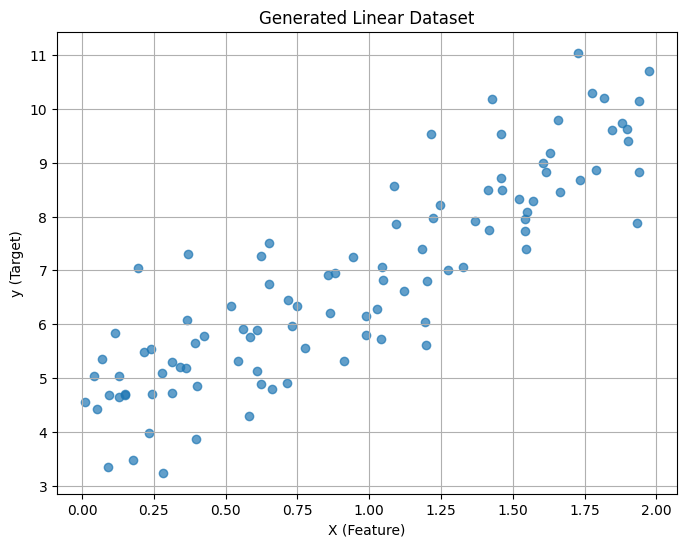

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

# Set a random seed for reproducibility
np.random.seed(42)

# Generate 100 data points
X = 2 * np.random.rand(100, 1) # Feature
y = 4 + 3 * X + np.random.randn(100, 1) # Target with noise

# Plot the generated data
plt.figure(figsize=(8, 6))
plt.scatter(X, y, alpha=0.7)
plt.xlabel('X (Feature)')
plt.ylabel('y (Target)')
plt.title('Generated Linear Dataset')
plt.grid(True)
plt.show()

### 2. Linear Regression with Plain Python (using NumPy for calculations)

This method involves implementing the core linear regression formulas directly. For simple linear regression ($y = \beta_0 + \beta_1x$), the coefficients can be calculated using the following formulas:

*   **Slope ($\beta_1$)**: $\beta_1 = \frac{\sum_{i=1}^{n} (x_i - \bar{x})(y_i - \bar{y})}{\sum_{i=1}^{n} (x_i - \bar{x})^2}$
*   **Intercept ($\beta_0$)**: $\beta_0 = \bar{y} - \beta_1\bar{x}$

Where $\bar{x}$ and $\bar{y}$ are the means of X and y, respectively.

Plain Python Coefficients:
  Slope (b1): 2.7701
  Intercept (b0): 4.2151


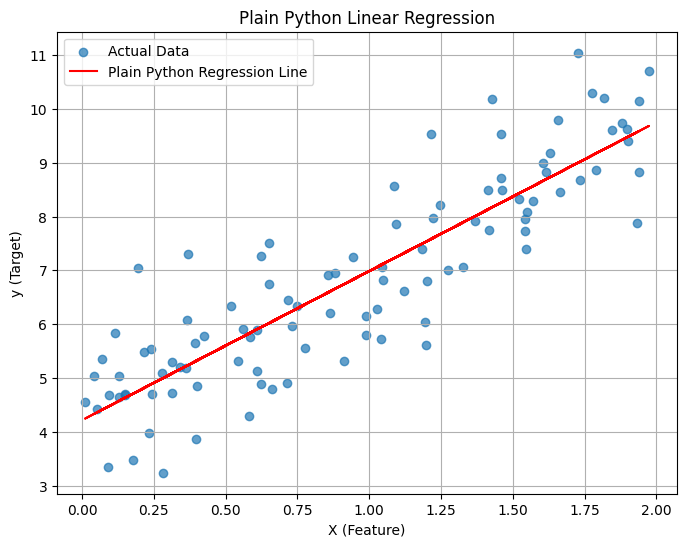

In [ ]:
# Calculate means
X_mean = np.mean(X)
y_mean = np.mean(y)

# Calculate numerator and denominator for the slope
numerator = np.sum((X - X_mean) * (y - y_mean))
denominator = np.sum((X - X_mean)**2)

# Calculate slope (b1) and intercept (b0)
b1_plain = numerator / denominator
b0_plain = y_mean - b1_plain * X_mean

print(f"Plain Python Coefficients:")
print(f"  Slope (b1): {b1_plain:.4f}")
print(f"  Intercept (b0): {b0_plain:.4f}")

# Make predictions
y_pred_plain = b0_plain + b1_plain * X

# Plot the regression line
plt.figure(figsize=(8, 6))
plt.scatter(X, y, alpha=0.7, label='Actual Data')
plt.plot(X, y_pred_plain, color='red', label='Plain Python Regression Line')
plt.xlabel('X (Feature)')
plt.ylabel('y (Target)')
plt.title('Plain Python Linear Regression')
plt.legend()
plt.grid(True)
plt.show()

# Shortcomings of Plain Python:
# 1. Manual Implementation: Requires understanding and implementing the formulas directly.
# 2. No Statistical Output: Doesn't provide standard statistical metrics like R-squared, p-values, standard errors, etc., out-of-the-box.
# 3. Limited to Simple Cases: Becomes very complex for multiple independent variables (multiple linear regression) or more advanced regression types.
# 4. Error Prone: More susceptible to implementation errors compared to using established libraries.
# 5. Performance: For very large datasets, optimized library implementations will generally be faster.

### 3. Linear Regression with Statsmodels

`statsmodels` is a Python library that provides classes and functions for the estimation of many different statistical models, as well as for conducting statistical tests and statistical data exploration. It excels in statistical inference.

We'll use the Ordinary Least Squares (OLS) model from `statsmodels`.

Statsmodels OLS Regression Results:
                            OLS Regression Results                            
Dep. Variable:                      y   R-squared:                       0.769
Model:                            OLS   Adj. R-squared:                  0.767
Method:                 Least Squares   F-statistic:                     326.7
Date:                Wed, 16 Sep 2026   Prob (F-statistic):           5.66e-33
Time:                        09:35:35   Log-Likelihood:                -131.15
No. Observations:                 100   AIC:                             266.3
Df Residuals:                      98   BIC:                             271.5
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const          4

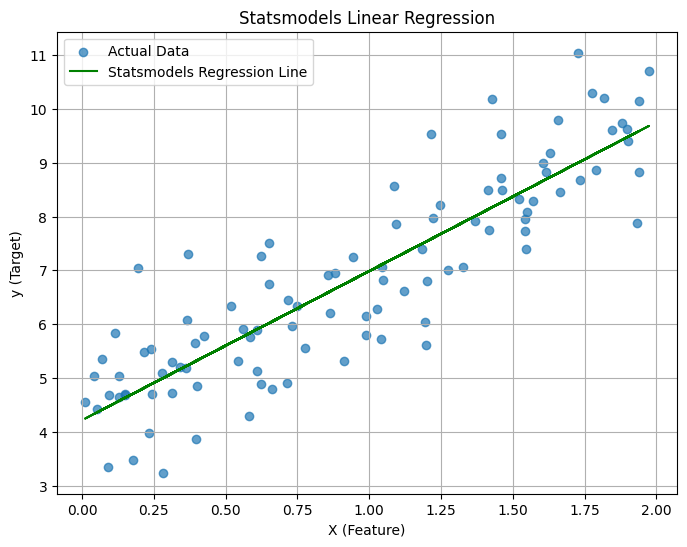

In [ ]:
import statsmodels.api as sm

# statsmodels requires an explicit constant (intercept) term
X_sm = sm.add_constant(X)

# Create an OLS model object
model_sm = sm.OLS(y, X_sm)

# Fit the model
results_sm = model_sm.fit()

# Print the summary of the regression results
print("Statsmodels OLS Regression Results:")
print(results_sm.summary())

# Extract coefficients
b0_sm, b1_sm = results_sm.params

# Make predictions
y_pred_sm = results_sm.predict(X_sm)

# Plot the regression line
plt.figure(figsize=(8, 6))
plt.scatter(X, y, alpha=0.7, label='Actual Data')
plt.plot(X, y_pred_sm, color='green', label='Statsmodels Regression Line')
plt.xlabel('X (Feature)')
plt.ylabel('y (Target)')
plt.title('Statsmodels Linear Regression')
plt.legend()
plt.grid(True)
plt.show()

# Shortcomings of Statsmodels:
# 1. Interface: The API can sometimes be less intuitive for users coming from a machine learning background (e.g., explicit addition of a constant for intercept).
# 2. Focus on Inference: While excellent for statistical inference, its primary focus isn't predictive performance or machine learning pipeline integration.
# 3. Data Preprocessing: Does not include advanced data preprocessing tools like scikit-learn.
# 4. Scalability: For very large datasets or complex machine learning workflows, scikit-learn might offer better performance and integration.

### 4. Linear Regression with Scikit-learn

`scikit-learn` is a widely used machine learning library in Python. It provides simple and efficient tools for predictive data analysis and is built upon `NumPy`, `SciPy`, and `Matplotlib`.

We'll use the `LinearRegression` model from `sklearn.linear_model`.

Scikit-learn Coefficients:
  Slope (b1): 2.7701
  Intercept (b0): 4.2151


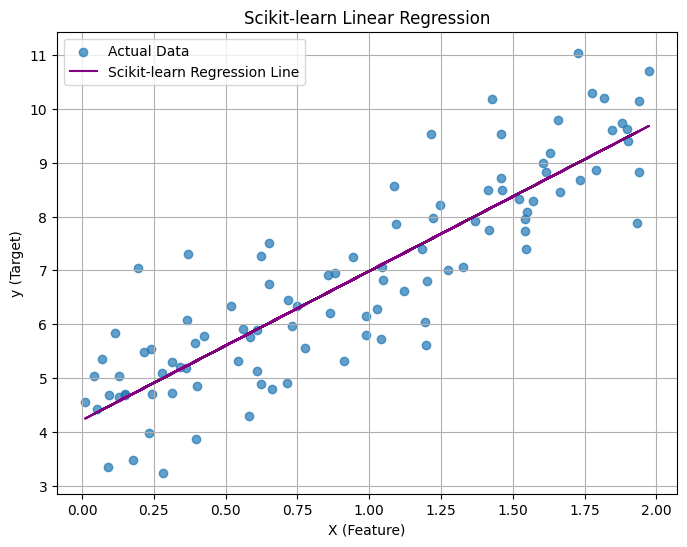

In [ ]:
from sklearn.linear_model import LinearRegression

# Create a Linear Regression model object
model_sklearn = LinearRegression()

# Fit the model to the data
model_sklearn.fit(X, y)

# Extract coefficients
b1_sklearn = model_sklearn.coef_[0][0]
b0_sklearn = model_sklearn.intercept_[0]

print(f"Scikit-learn Coefficients:")
print(f"  Slope (b1): {b1_sklearn:.4f}")
print(f"  Intercept (b0): {b0_sklearn:.4f}")

# Make predictions
y_pred_sklearn = model_sklearn.predict(X)

# Plot the regression line
plt.figure(figsize=(8, 6))
plt.scatter(X, y, alpha=0.7, label='Actual Data')
plt.plot(X, y_pred_sklearn, color='purple', label='Scikit-learn Regression Line')
plt.xlabel('X (Feature)')
plt.ylabel('y (Target)')
plt.title('Scikit-learn Linear Regression')
plt.legend()
plt.grid(True)
plt.show()

# Shortcomings of Scikit-learn (for purely statistical inference):
# 1. Less Statistical Detail: Scikit-learn primarily focuses on prediction and provides less detailed statistical output (e.g., p-values for coefficients, standard errors) compared to `statsmodels`.
# 2. No Direct Summary: There isn't a direct equivalent to `statsmodels`' `summary()` method that provides a comprehensive statistical report.
# 3. Interpretability: While it provides coefficients, interpreting their statistical significance directly from the output requires additional steps or using other libraries.
# 4. More for ML Workflows: Best suited for integration into larger machine learning pipelines, rather than standalone statistical analysis for inference.

### Conclusion

Each method has its strengths and ideal use cases:

*   **Plain Python:** Good for understanding the underlying math, but not practical for real-world analysis due to lack of features and statistical output.
*   **Statsmodels:** Excellent for **statistical inference**, providing detailed reports with p-values, R-squared, and standard errors, crucial for understanding the statistical significance of variables and model fit.
*   **Scikit-learn:** Ideal for **predictive modeling** and integration into machine learning pipelines, focusing on performance, ease of use, and compatibility with other ML tools.

### 5. Model Evaluation

Let's evaluate the performance of our linear regression models using standard metrics: Mean Squared Error (MSE), Root Mean Squared Error (RMSE), Mean Absolute Error (MAE), and R-squared. These metrics will help us quantify how well each model fits the data and makes predictions.

In [ ]:
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

# --- Plain Python Model Evaluation ---
# Note: R-squared for plain python needs to be calculated manually or using sklearn's r2_score function
plain_r2 = r2_score(y, y_pred_plain)
plain_mse = mean_squared_error(y, y_pred_plain)
plain_rmse = np.sqrt(plain_mse)
plain_mae = mean_absolute_error(y, y_pred_plain)

print("--- Plain Python Model Evaluation ---")
print(f"R-squared: {plain_r2:.4f}")
print(f"Mean Squared Error (MSE): {plain_mse:.4f}")
print(f"Root Mean Squared Error (RMSE): {plain_rmse:.4f}")
print(f"Mean Absolute Error (MAE): {plain_mae:.4f}")
print("\n")

# --- Statsmodels Model Evaluation ---
# Statsmodels summary already provides R-squared. We can extract other metrics.
stats_r2 = results_sm.rsquared
stats_mse = mean_squared_error(y, y_pred_sm)
stats_rmse = np.sqrt(stats_mse)
stats_mae = mean_absolute_error(y, y_pred_sm)

print("--- Statsmodels Model Evaluation ---")
print(f"R-squared: {stats_r2:.4f}")
print(f"Mean Squared Error (MSE): {stats_mse:.4f}")
print(f"Root Mean Squared Error (RMSE): {stats_rmse:.4f}")
print(f"Mean Absolute Error (MAE): {stats_mae:.4f}")
print("\n")

# --- Scikit-learn Model Evaluation ---
sklearn_r2 = model_sklearn.score(X, y) # R-squared from the model itself
sklearn_mse = mean_squared_error(y, y_pred_sklearn)
sklearn_rmse = np.sqrt(sklearn_mse)
sklearn_mae = mean_absolute_error(y, y_pred_sklearn)

print("--- Scikit-learn Model Evaluation ---")
print(f"R-squared: {sklearn_r2:.4f}")
print(f"Mean Squared Error (MSE): {sklearn_mse:.4f}")
print(f"Root Mean Squared Error (RMSE): {sklearn_rmse:.4f}")
print(f"Mean Absolute Error (MAE): {sklearn_mae:.4f}")

--- Plain Python Model Evaluation ---
R-squared: 0.7693
Mean Squared Error (MSE): 0.8066
Root Mean Squared Error (RMSE): 0.8981
Mean Absolute Error (MAE): 0.7010


--- Statsmodels Model Evaluation ---
R-squared: 0.7693
Mean Squared Error (MSE): 0.8066
Root Mean Squared Error (RMSE): 0.8981
Mean Absolute Error (MAE): 0.7010


--- Scikit-learn Model Evaluation ---
R-squared: 0.7693
Mean Squared Error (MSE): 0.8066
Root Mean Squared Error (RMSE): 0.8981
Mean Absolute Error (MAE): 0.7010


### Explanation of Evaluation Metrics

Let's break down what each of these metrics tells us about our model's performance:

*   **R-squared ($R^2$)**:
    *   **Meaning**: Represents the proportion of the variance in the dependent variable (y) that is predictable from the independent variable(s) (X). It indicates how well the independent variables explain the variation in the dependent variable.
    *   **Interpretation**: Values range from 0 to 1. A higher R-squared value (closer to 1) indicates that a larger proportion of variance is explained by the model, implying a better fit. An R-squared of 0 means the model explains none of the variability of the response data around its mean.

*   **Mean Squared Error (MSE)**:
    *   **Meaning**: The average of the squares of the errors (the difference between the actual observed values and the values predicted by the model). It measures the average magnitude of the errors, with larger errors contributing more to the MSE due to squaring.
    *   **Interpretation**: MSE values are always non-negative, and a value closer to zero is better. Because errors are squared, MSE is very sensitive to outliers. The unit of MSE is the square of the unit of the dependent variable (e.g., if y is in dollars, MSE is in dollars squared).

*   **Root Mean Squared Error (RMSE)**:
    *   **Meaning**: The square root of the MSE. It's an extension of MSE that provides the error in the same units as the dependent variable.
    *   **Interpretation**: RMSE is easier to interpret than MSE because it's in the same units as the target variable. Like MSE, a lower RMSE indicates a better fit. It's also sensitive to outliers.

*   **Mean Absolute Error (MAE)**:
    *   **Meaning**: The average of the absolute differences between the actual observed values and the values predicted by the model. It measures the average magnitude of the errors without considering their direction.
    *   **Interpretation**: MAE is less sensitive to outliers compared to MSE/RMSE because it doesn't square the errors. A lower MAE indicates better model performance. Its unit is the same as the unit of the dependent variable.

In our case, all three models yielded very similar, good results across these metrics, which is expected since they are all solving the same simple linear regression problem on the same dataset.